# SAM-6D Usage Example

This notebook walks through the full SAM-6D pipeline using the `SAM6D` class in `src/sam6d.py`.

**Pipeline at a glance:**
1. **Init** — loads SAM + DINOv2 (ISM) and a ViT pose estimation model (PEM), renders CAD templates with BlenderProc, computes reference descriptors
2. **Forward** — given an RGBD frame (RGB image, depth map, camera intrinsics), returns 6DoF poses (R, t), proposal masks, and per-stage confidence scores

Rendered templates and descriptors are cached to `template_dir`, so subsequent runs skip the rendering and embedding steps.

In [1]:
import sys
sys.path.insert(0, "..")  # add repo root if running from a subdirectory

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

from src.sam6d import SAM6D

/home/joon/.virtualenvs/cnos2/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## 1. Configuration

Point `CAD_PATH` at your object's CAD file (`.ply`, `.stl`, `.obj`, etc.).

Checkpoint weights are auto-downloaded on first run if not already present.

**Camera intrinsics** are read directly from the RealSense camera at startup — no manual K matrix needed.

**Depth convention:** the RealSense depth stream is in **millimetres** (z16 = uint16 mm), so `depth_scale` stays `1.0`.

In [2]:
FX, FY, CX, CY = 604.7352294921875, 604.958984375, 430.3172302246094, 245.13461303710938
K = np.array([
    [FX,  0,  CX],
    [0,  FY,  CY],
    [0,   0,   1],
], dtype=np.float32)

In [3]:
# import pyrealsense2 as rs

# # --- Paths --- adjust these to your setup
# CAD_PATH     = "/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/carrier_v5-Flipper_v7motor_adapter.stl"
# TEMPLATE_DIR = "./sam6d_templates"   # rendered views + descriptors are cached here

# DEPTH_SCALE = 1.0   # multiply raw depth pixels → mm (1.0 if already mm)

# # Optional: apply a solid color to colorless meshes (e.g. STL files without texture)
# MESH_COLOR = (0, int(0.35*255), int(0.95*255))  # RGB 0-255, or None to leave as-is

# # Optional: use flat shading so that flat faces render flat (helps for CAD/STL)
# FLAT_SHADING = True

# DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# # --- Camera intrinsics from RealSense ---
# SERIAL_NUMBER = '243322070950'
# WIDTH, HEIGHT, FPS = 848, 480, 30

# rs_pipeline = rs.pipeline()
# rs_config   = rs.config()

# rs_context = rs.context()
# if len(rs_context.query_devices()) == 0:
#     raise RuntimeError(
#         "[Camera] No RealSense devices detected. "
#         "Check USB connection and that Terminal has Camera permission "
#         "(System Settings → Privacy & Security → Camera)."
#     )

# rs_config.enable_device(SERIAL_NUMBER)
# rs_config.enable_stream(rs.stream.depth, WIDTH, HEIGHT, rs.format.z16,  FPS)
# rs_config.enable_stream(rs.stream.color, WIDTH, HEIGHT, rs.format.rgb8, FPS)

# rs_profile    = rs_pipeline.start(rs_config)
# color_profile = rs_profile.get_stream(rs.stream.color)
# intr          = color_profile.as_video_stream_profile().get_intrinsics()
# rs_pipeline.stop()

# K = np.array([
#     [intr.fx,    0,       intr.ppx],
#     [0,          intr.fy, intr.ppy],
#     [0,          0,       1       ],
# ], dtype=np.float32)

# print(f"Using device: {DEVICE}")
# print(f"Camera intrinsics ({WIDTH}x{HEIGHT}):")
# print(f"  fx={intr.fx:.4f}  fy={intr.fy:.4f}  cx={intr.ppx:.4f}  cy={intr.ppy:.4f}")
# print(f"K =\n{K}")

In [4]:
# --- Paths --- adjust these to your setup
CAD_PATH     = "/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/carrier_v5-gear_bigger_dummy.stl"
TEMPLATE_DIR = "./sam6d_templates"   # rendered views + descriptors are cached here

# Camera intrinsic matrix (3x3) — replace with your actual camera K
# K = np.array([
#     [572.4114,   0.    , 325.2611],
#     [  0.    , 573.5704, 242.0490],
#     [  0.    ,   0.    ,   1.    ],
# ], dtype=np.float32)

DEPTH_SCALE = 1000.0   # multiply raw depth pixels → mm (1.0 if already mm)

# Optional: apply a solid color to colorless meshes (e.g. STL files without texture)
MESH_COLOR = (int(0.0*255), int(0.35*255), int(0.95*255))  # RGB 0-255, or None to leave as-is

# Optional: use flat shading so that flat faces render flat (helps for CAD/STL)
FLAT_SHADING = True

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

Using device: cuda


## 2. Initialize SAM6D

Initialization renders 42 BlenderProc templates (skipped if already cached), computes ISM reference descriptors, and pre-extracts PEM template point-cloud features.

Key parameters:
- `sam_model_type`: `"vit_h"` (default, best quality), `"vit_l"`, `"vit_b"` (fastest)
- `n_template_view`: how many of the 42 rendered views PEM uses (42 = all, fewer = faster)
- `det_score_thresh`: ISM proposals below this score are dropped before pose estimation
- `confidence_thresh`: minimum DINOv2 semantic similarity to even consider a proposal
- `mesh_color`: RGB tuple (0–255) applied to colorless meshes (e.g. STL); `None` leaves textures as-is
- `flat_shading`: set `True` to disable normal interpolation so flat faces render flat
- `roughness`: Principled BSDF roughness — `0.0` = mirror/glossy, `1.0` = fully matte (`None` = Blender default 0.5)
- `metallic`: Principled BSDF metallic weight — `0.0` = plastic, `1.0` = metallic conductor (`None` = Blender default 0.0)
- `light_energy`: point light brightness in watts (default `1000`)
- `min_component_area_ratio`: drop disconnected mask blobs smaller than this fraction of the largest blob (0 = off)
- `mask_overlap_thresh`: suppress the lower-scoring detection when two masks overlap by more than this fraction of the smaller mask's area (0 = off)

In [28]:
model = SAM6D(
    cad_path=CAD_PATH,
    device=DEVICE,

    # Segmentor
    sam_model_type="vit_h",
    stability_score_thresh=0.96,

    # Template rendering
    template_dir=TEMPLATE_DIR,
    reset_templates=False,   # set True to force re-render
    mesh_color=MESH_COLOR,   # RGB (0-255) for colorless meshes, or None
    flat_shading=FLAT_SHADING,  # True = flat faces render flat
    roughness=0.8,              # 0.0 = mirror/glossy, 1.0 = fully matte
    metallic=0.0,               # 0.0 = plastic/dielectric, 1.0 = metallic
    light_energy=600,          # point light brightness in watts

    # Matching / filtering
    det_score_thresh=0.45,
    confidence_thresh=0.45,
    visible_thred=0.15,
    n_template_view=42,
    min_component_area_ratio=0.005,  # drop disconnected mask blobs < 0.5% of largest
    mask_overlap_thresh=0.9,         # suppress lower-scoring mask if overlap > 90%
    pose_score_thresh=0.3,           # drop detections with pose score below this (0=off)
)

load pre-trained checkpoint from: checkpoints/mae_pretrain_vit_base.pth


## 3. Load RGBD Data

Replace the paths below with your actual RGB image and depth map.
The depth map should be a single-channel image (uint16 or float) with values in mm.

In [85]:
# --- Load your RGBD frame here ---
import pickle

# Load an object from a file
with open('/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/data_cap_depth_.pkl', 'rb') as file:
    loaded_data = pickle.load(file)

[captures, depth_predictions] = loaded_data

rgb   = captures[1][0]
depth = captures[1][1]

print(f"RGB shape:   {rgb.shape}")
print(f"Depth shape: {depth.shape}")
print(f"Depth range: {depth.min():.1f} – {depth.max():.1f} mm")

RGB shape:   (480, 848, 3)
Depth shape: (480, 848)
Depth range: 0.0 – 5.8 mm


## 4. Run Forward Pass

`forward()` accepts an RGB array/PIL image, a depth map (mm), and camera intrinsics, and returns a dict with poses and all intermediate scores.

In [86]:
results = model(rgb, depth, K, depth_scale=DEPTH_SCALE)   # or model.forward(...)

N = len(results["poses"])
print(f"Detections passing threshold: {N}")
print()
print(f"masks:             {results['masks'].shape}         # [N, H, W] bool")
print(f"boxes:             {results['boxes'].shape}         # [N, 4] xyxy")
print(f"ism_scores:        {results['ism_scores'].shape}    # [N] final ISM confidence")
print(f"semantic_scores:   {results['semantic_scores'].shape}")
print(f"appe_scores:       {results['appe_scores'].shape}")
print(f"geometric_scores:  {results['geometric_scores'].shape}")
print(f"pred_R:            {results['pred_R'].shape}        # [N, 3, 3]")
print(f"pred_t:            {results['pred_t'].shape}        # [N, 3]  (mm)")
print(f"pose_scores:       {results['pose_scores'].shape}")

if N > 0:
    best = np.argmax(results['pose_scores'])
    print(f"\nBest pose (detection {best}, score={results['pose_scores'][best]:.3f}):")
    print(f"  R =\n{results['pred_R'][best]}")
    print(f"  t = {results['pred_t'][best]} mm")

Detections passing threshold: 1

masks:             (1, 480, 848)         # [N, H, W] bool
boxes:             (1, 4)         # [N, 4] xyxy
ism_scores:        (1,)    # [N] final ISM confidence
semantic_scores:   (1,)
appe_scores:       (1,)
geometric_scores:  (1,)
pred_R:            (1, 3, 3)        # [N, 3, 3]
pred_t:            (1, 3)        # [N, 3]  (mm)
pose_scores:       (1,)

Best pose (detection 0, score=0.567):
  R =
[[-0.98134714  0.10295442  0.1623506 ]
 [-0.05976182  0.6392904  -0.76663923]
 [-0.18271816 -0.76204205 -0.6212132 ]]
  t = [-67.38611   42.978386 255.56415 ] mm


## 5. Visualize Detections

Each detection is shown with its ISM mask overlay and bounding box. The best-scoring pose is highlighted.

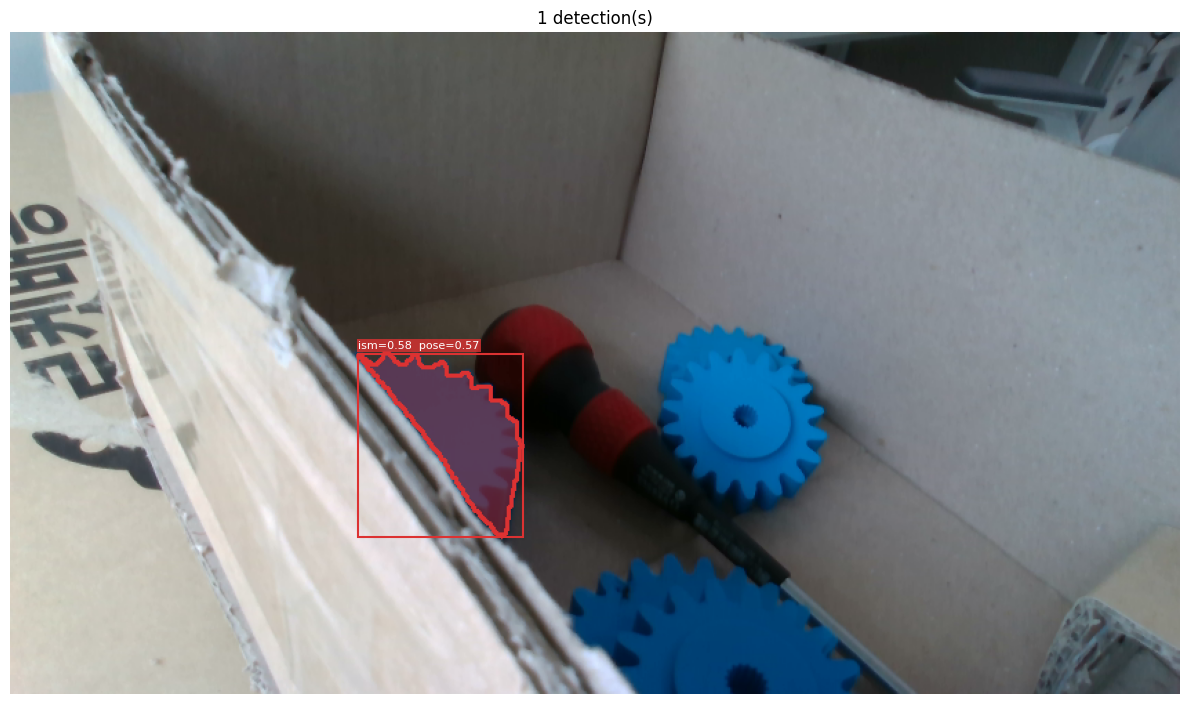

In [87]:
def visualize_detections(rgb, results, alpha=0.4):
    import cv2

    COLORS = [
        "#DC3232", "#1EC8C8", "#3264DC", "#32B432",
        "#A032DC", "#F08C1E", "#E650B4", "#C8C828",
    ]

    def hex_to_rgb(h):
        h = h.lstrip("#")
        return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)])

    masks       = results["masks"]       # [N, H, W] bool
    boxes       = results["boxes"]       # [N, 4] xyxy
    ism_scores  = results["ism_scores"]
    pose_scores = results["pose_scores"]

    if len(masks) == 0:
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.imshow(rgb)
        ax.set_title("No detections")
        ax.axis("off")
        plt.show()
        return

    colors = [hex_to_rgb(COLORS[i % len(COLORS)]) for i in range(len(masks))]

    order   = np.argsort([-m.sum() for m in masks])
    overlay = rgb.copy().astype(float)
    for i in order:
        mask = masks[i].astype(bool)
        overlay[mask] = (1 - alpha) * overlay[mask] + alpha * colors[i]

    canvas = overlay.astype(np.uint8)
    for i in order:
        contours, _ = cv2.findContours(
            masks[i].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(canvas, contours, -1, colors[i].tolist(), 2)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(canvas)

    for i, (box, ism_s, pose_s) in enumerate(zip(boxes, ism_scores, pose_scores)):
        x1, y1, x2, y2 = box
        color = colors[i] / 255.0
        lw = 1.5
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=lw, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        label = f"ism={ism_s:.2f}  pose={pose_s:.2f}"
        ax.text(
            x1, y1 - 4, label,
            color="white", fontsize=8,
            bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"),
        )

    ax.axis("off")
    ax.set_title(f"{len(masks)} detection(s)")
    plt.tight_layout()
    plt.show()


visualize_detections(rgb, results)

## 6. Project Poses onto Image

All detections are overlaid on the image with their CAD point cloud and coordinate axes.
The **best-scoring** detection uses orange dots and thick axes; others use grey dots and thin axes.

Axes convention: **X = blue**, **Y = green**, **Z = red** (OpenCV camera frame).
Adjust `axis_len_mm` to match your object's scale.

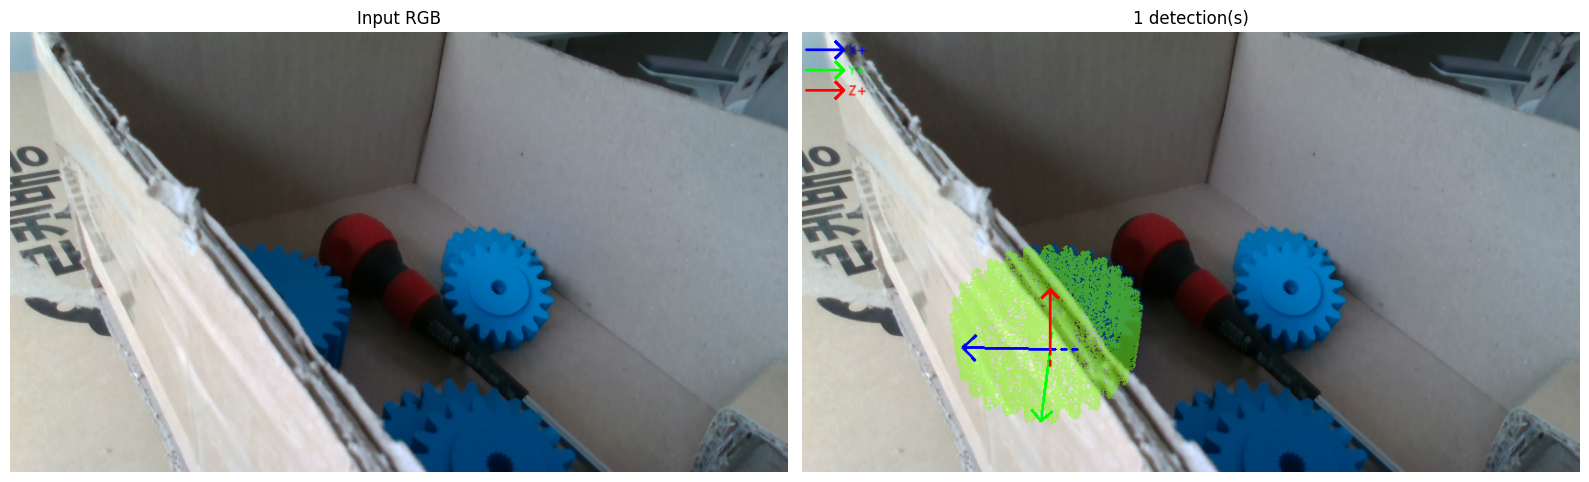

In [88]:
def project_all_poses(rgb, results, K, cad_path, n_pts=1024, axis_len_mm=38.0):
    import trimesh, cv2

    poses       = results['poses']
    pose_scores = results['pose_scores']
    if len(poses) == 0:
        print('No detections — nothing to project.')
        return

    mesh    = trimesh.load_mesh(cad_path)
    pts_mm  = mesh.sample(n_pts).astype(np.float32)
    best_i  = int(np.argmax(pose_scores))

    fx, fy, cx, cy = K[0,0], K[1,1], K[0,2], K[1,2]
    H, W = rgb.shape[:2]

    def project(pts_cam):
        u = (pts_cam[:, 0] * fx / pts_cam[:, 2] + cx).astype(int)
        v = (pts_cam[:, 1] * fy / pts_cam[:, 2] + cy).astype(int)
        valid = (u >= 0) & (u < W) & (v >= 0) & (v < H) & (pts_cam[:, 2] > 0)
        return u, v, valid

    def pt2img(p_obj, R, t_mm):
        p_cam = R @ p_obj + t_mm
        if p_cam[2] <= 0:
            return None
        return (int(p_cam[0] * fx / p_cam[2] + cx),
                int(p_cam[1] * fy / p_cam[2] + cy))

    def draw_dashed_line(img, p1, p2, color, thickness=1, gap=6):
        """Draw a dashed line from p1 to p2."""
        dx, dy = p2[0] - p1[0], p2[1] - p1[1]
        dist = max(1, int((dx**2 + dy**2) ** 0.5))
        for i in range(0, dist, gap * 2):
            t0, t1 = i / dist, min((i + gap) / dist, 1.0)
            a = (int(p1[0] + t0 * dx), int(p1[1] + t0 * dy))
            b = (int(p1[0] + t1 * dx), int(p1[1] + t1 * dy))
            cv2.line(img, a, b, color, thickness)

    canvas = rgb.copy()
    overlay = canvas.copy()

    # --- point cloud ---
    for idx, pose in enumerate(poses):
        R, t = pose['R'], pose['t']
        pts_cam = (R @ pts_mm.T).T + t[None, :]
        u, v, valid = project(pts_cam)
        dot_color = (255 // 2, 255, 0)
        for ui, vi in zip(u[valid], v[valid]):
            cv2.circle(overlay, (ui, vi), 1, dot_color, -1)

    canvas = cv2.addWeighted(canvas, 0.5, overlay, 0.5, 0)

    # --- axes ---
    AXIS_COLORS = [(0, 0, 255), (0, 255, 0), (255, 0, 0)]  # X=blue, Y=green, Z=red
    NEG_LEN = 0.35   # negative stub = 35% of axis_len_mm

    for idx, pose in enumerate(poses):
        R, t = pose['R'], pose['t']
        o_img = pt2img(np.zeros(3), R, t)
        if o_img is None:
            continue
        thickness = 2

        for axis_idx, color in enumerate(AXIS_COLORS):
            unit = np.zeros(3); unit[axis_idx] = 1.0

            # positive direction: solid arrow
            tip = pt2img(unit * axis_len_mm, R, t)
            if tip is not None:
                cv2.arrowedLine(canvas, o_img, tip, color, thickness, tipLength=0.2)

            # negative direction: dashed stub so you can read +/- orientation
            neg_tip = pt2img(-unit * axis_len_mm * NEG_LEN, R, t)
            if neg_tip is not None:
                draw_dashed_line(canvas, o_img, neg_tip, color, thickness)

    # --- legend ---
    for i, (lbl, color) in enumerate([("X+", (0,0,255)), ("Y+", (0,255,0)), ("Z+", (255,0,0))]):
        y = 20 + i * 22
        cv2.arrowedLine(canvas, (10, y), (45, y), color, 2, tipLength=0.35)
        draw_dashed_line(canvas, (10, y), (2, y), color, 2)  # neg stub sample
        cv2.putText(canvas, lbl, (50, y + 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(rgb)
    axes[0].set_title("Input RGB")
    axes[0].axis("off")
    axes[1].imshow(canvas)
    axes[1].set_title(
        f"{len(poses)} detection(s)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


project_all_poses(rgb, results, K, CAD_PATH, n_pts=4096*4)

## 7. Inspect Intermediate Score Distributions

SAM-6D's ISM computes three complementary scores per proposal before passing to PEM:
- **Semantic** — DINOv2 CLS-token cosine similarity to reference templates
- **Appearance** — masked patch-token similarity (texture/appearance)
- **Geometric** — IoU between projected template point cloud and proposal bbox (depth-aware)

Inspecting these independently is useful for diagnosing failures.

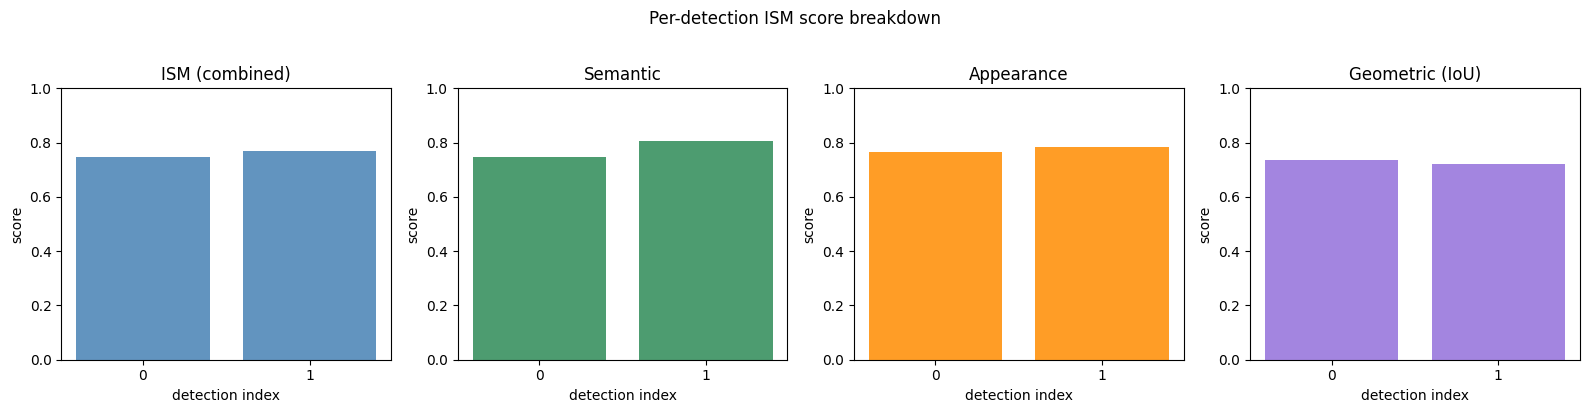

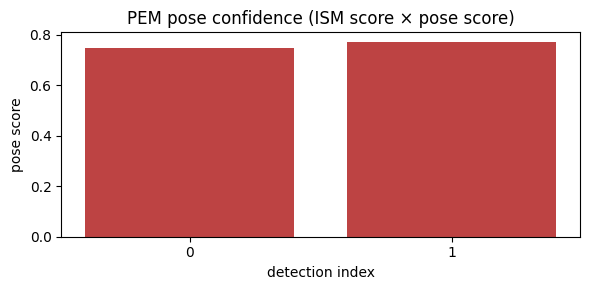

In [42]:
if len(results["ism_scores"]) > 0:
    N = len(results["ism_scores"])
    det_ids = np.arange(N)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)

    score_data = [
        ("ISM (combined)",  results["ism_scores"],       "steelblue"),
        ("Semantic",        results["semantic_scores"],  "seagreen"),
        ("Appearance",      results["appe_scores"],      "darkorange"),
        ("Geometric (IoU)", results["geometric_scores"], "mediumpurple"),
    ]

    for ax, (title, vals, color) in zip(axes, score_data):
        ax.bar(det_ids, vals, color=color, alpha=0.85)
        ax.set_title(title)
        ax.set_xlabel("detection index")
        ax.set_ylabel("score")
        ax.set_xticks(det_ids)
        ax.set_ylim(0, 1)

    plt.suptitle("Per-detection ISM score breakdown", y=1.02)
    plt.tight_layout()
    plt.show()

    # PEM confidence
    fig, ax = plt.subplots(figsize=(max(6, N * 0.8), 3))
    ax.bar(det_ids, results["pose_scores"], color="firebrick", alpha=0.85)
    ax.set_title("PEM pose confidence (ISM score × pose score)")
    ax.set_xlabel("detection index")
    ax.set_ylabel("pose score")
    ax.set_xticks(det_ids)
    plt.tight_layout()
    plt.show()
else:
    print("No detections to display.")